In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
try:
    df = pd.read_csv('BDM_Data.csv', index_col='Indicator')
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: 'tata_motors_data.csv' not found.")

Dataset loaded successfully.


In [ ]:
df.head()

,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
Indicator,,,,,,,,,,
Revenue (₹ Cr),278546.0,275247.0,294243.0,301938.0,261068.0,249795.0,278454.0,345969.0,437928.0,439695.0
EBITDA (₹ Cr),2740.0,36912.0,31121.0,25765.0,12851.0,27249.0,28932.0,37042.0,62798.0,57649.0
PBT (₹ Cr),13981.0,9315.0,11155.0,31371.0,10579.0,10474.0,7003.0,993.0,28932.0,34330.0
PAT (₹ Cr),11024.0,7454.0,8988.0,28826.0,12070.0,13451.0,11441.0,2728.0,3057.0,28149.0
Net Cash from Operations (₹ Cr),37900.0,30199.0,23857.0,18890.0,26632.0,29001.0,11441.0,35388.0,2414.0,63102.0


In [ ]:
df.shape

(46, 10)

In [ ]:
print("\n--- DataFrame Information ---")
df.info()


--- DataFrame Information ---
<class 'pandas.core.frame.DataFrame'>
Index: 46 entries, Revenue (₹ Cr) to C.I.F. value of imports - Raw material and components
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   2015-16  46 non-null     float64
 1   2016-17  46 non-null     float64
 2   2017-18  46 non-null     float64
 3   2018-19  46 non-null     float64
 4   2019-20  46 non-null     float64
 5   2020-21  46 non-null     float64
 6   2021-22  46 non-null     float64
 7   2022-23  46 non-null     float64
 8   2023-24  46 non-null     float64
 9   2024-25  46 non-null     float64
dtypes: float64(10)
memory usage: 4.0+ KB


In [ ]:
df_transposed = df.T
df_transposed = df_transposed.apply(pd.to_numeric, errors='coerce')

print("\n--- Summary Statistics (Financial Indicators) ---")
financial_indicators = ['Revenue (₹ Cr)', 'EBITDA (₹ Cr)', 'PAT (₹ Cr)']
print(df_transposed[financial_indicators].describe())

print("\n--- Summary Statistics (Operational Indicators) ---")
operational_indicators = ['Vehicle Sales (Total units)', 'Capital Expenditure (₹ Cr)']
print(df_transposed[operational_indicators].describe())


--- Summary Statistics (Financial Indicators) ---
Indicator  Revenue (₹ Cr)  EBITDA (₹ Cr)    PAT (₹ Cr)
count           10.000000       10.00000     10.000000
mean        316288.300000    32305.90000  12718.800000
std          69609.422083    18102.99563   9054.149408
min         249795.000000     2740.00000   2728.000000
25%         276048.750000    26136.00000   7837.500000
50%         286394.500000    30026.50000  11232.500000
75%         334961.250000    37009.50000  13105.750000
max         439695.000000    62798.00000  28826.000000

--- Summary Statistics (Operational Indicators) ---
Indicator  Vehicle Sales (Total units)  Capital Expenditure (₹ Cr)
count                     1.000000e+01                   10.000000
mean                      1.186153e+06                33660.000000
std                       1.380067e+05                 4883.982414
min                       9.614630e+05                27049.000000
25%                       1.080227e+06                31030.000000

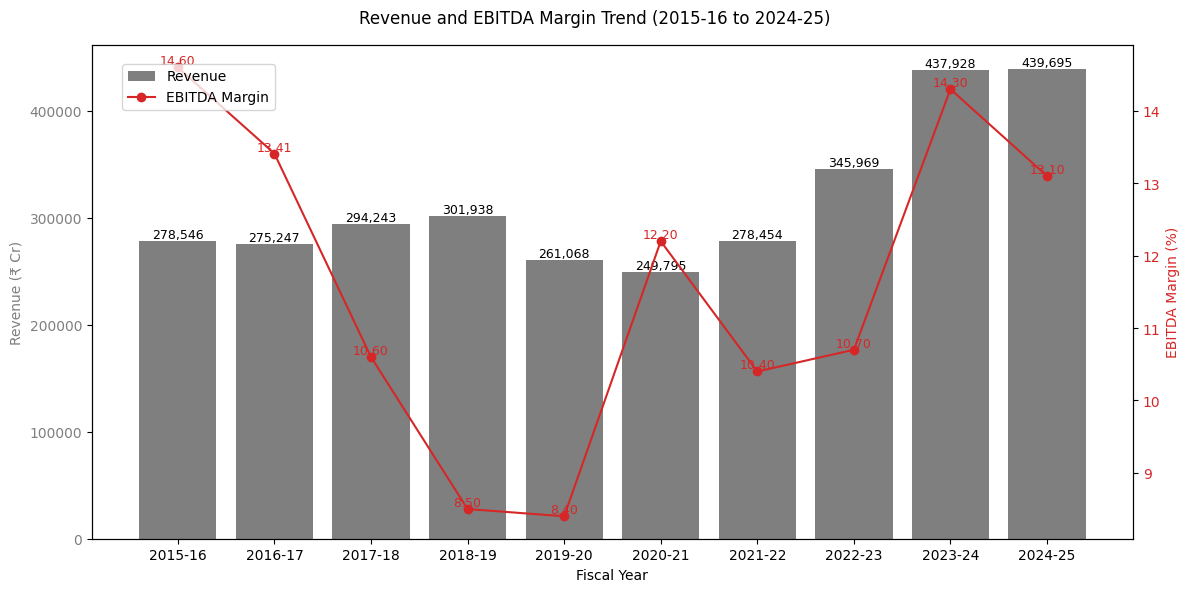

In [ ]:
# Create a figure and a set of subplots
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Revenue as a bar chart on the primary axis (ax1)
color = 'tab:gray'
ax1.set_xlabel('Fiscal Year')
ax1.set_ylabel('Revenue (₹ Cr)', color=color)
ax1.bar(df_transposed.index, df_transposed['Revenue (₹ Cr)'], color=color, label='Revenue')
ax1.tick_params(axis='y', labelcolor=color)

# Create a second axes that shares the same x-axis
ax2 = ax1.twinx()

# Plot EBITDA Margin as a line chart on the secondary axis (ax2)
color = 'tab:red'
ax2.set_ylabel('EBITDA Margin (%)', color=color)
ax2.plot(df_transposed.index, df_transposed['EBITDA Margin (%)'], color=color, marker='o', label='EBITDA Margin')
ax2.tick_params(axis='y', labelcolor=color)

# Add value labels to the bars and line plot points for clarity
for i, (year, revenue, margin) in enumerate(zip(df_transposed.index, df_transposed['Revenue (₹ Cr)'], df_transposed['EBITDA Margin (%)'])):
    ax1.text(i, revenue, f'{revenue:,.0f}', ha='center', va='bottom', fontsize=9)
    ax2.text(i, margin, f'{margin:.2f}', ha='center', va='bottom', fontsize=9, color=color)

# Set the title and legends
fig.suptitle('Revenue and EBITDA Margin Trend (2015-16 to 2024-25)')
fig.tight_layout()
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.show()

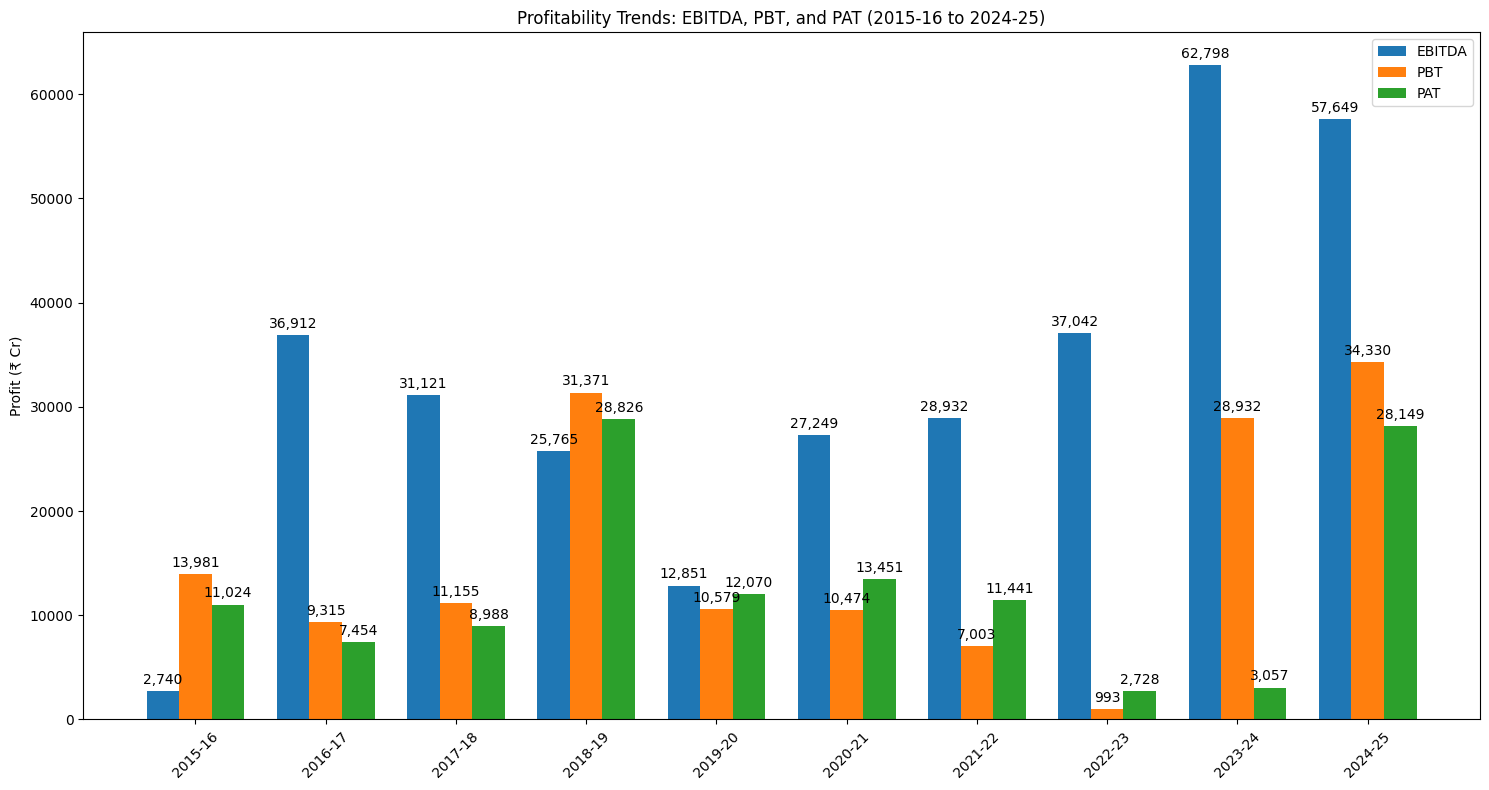

In [ ]:
df_profits = df.loc[['EBITDA (₹ Cr)', 'PBT (₹ Cr)', 'PAT (₹ Cr)']].T # Simplify column names for the plot

# Convert the data to numeric, handling any non-numeric values
df_profits = df_profits.apply(pd.to_numeric, errors='coerce')

# Set up the plot
years = df_profits.index
x = np.arange(len(years))  # The label locations
width = 0.25  # The width of the bars

fig, ax = plt.subplots(figsize=(15, 8))

# Plot each set of bars
rects1 = ax.bar(x - width, df_profits['EBITDA (₹ Cr)'], width, label='EBITDA')
rects2 = ax.bar(x, df_profits['PBT (₹ Cr)'], width, label='PBT')
rects3 = ax.bar(x + width, df_profits['PAT (₹ Cr)'], width, label='PAT')

# Add some text for labels, title, and custom x-axis tick labels
ax.set_ylabel('Profit (₹ Cr)')
ax.set_title('Profitability Trends: EBITDA, PBT, and PAT (2015-16 to 2024-25)')
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:,.0f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

# Apply the labels
autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
plt.show()

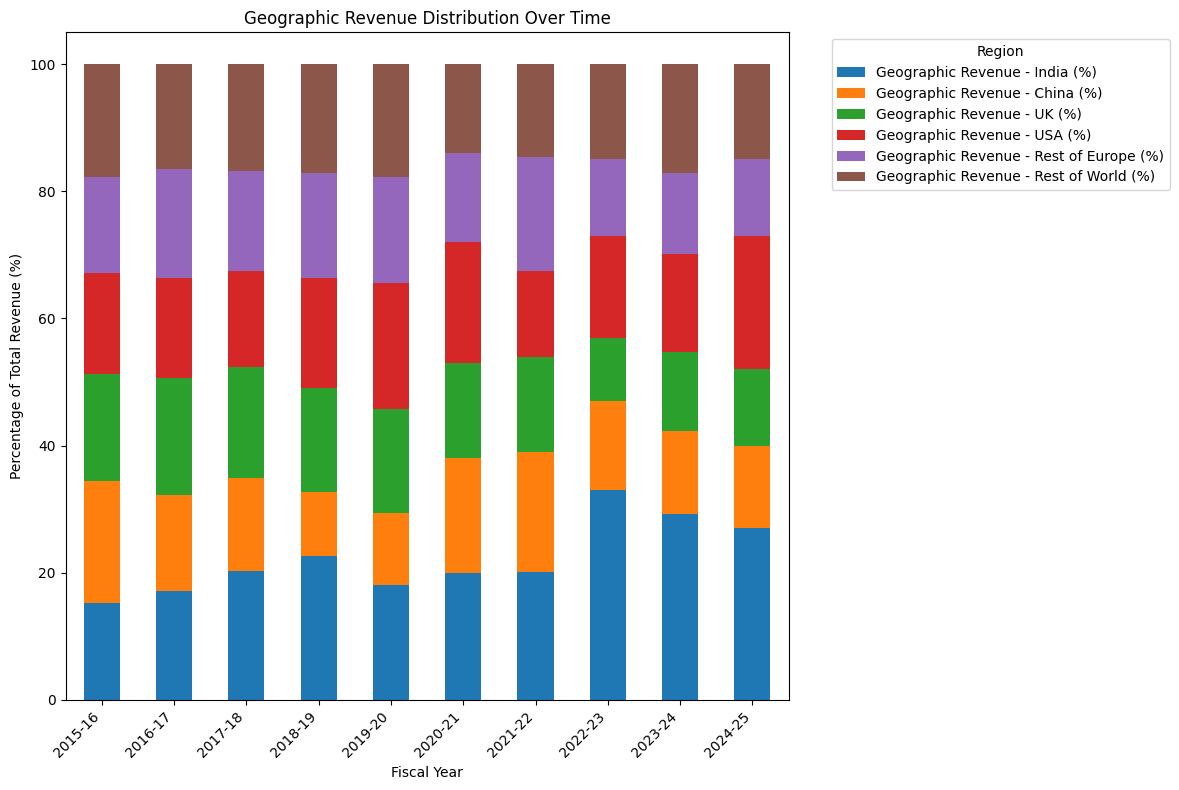

In [ ]:
# Filter for geographic revenue data and transpose for plotting
df_geography = df[df.index.str.contains('Geographic Revenue')].T
df_geography.index.name = 'Fiscal Year'

# Create the stacked bar chart
df_geography.plot(kind='bar', stacked=True, figsize=(12, 8))

# Add a title and labels
plt.title('Geographic Revenue Distribution Over Time')
plt.xlabel('Fiscal Year')
plt.ylabel('Percentage of Total Revenue (%)')
plt.legend(title='Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

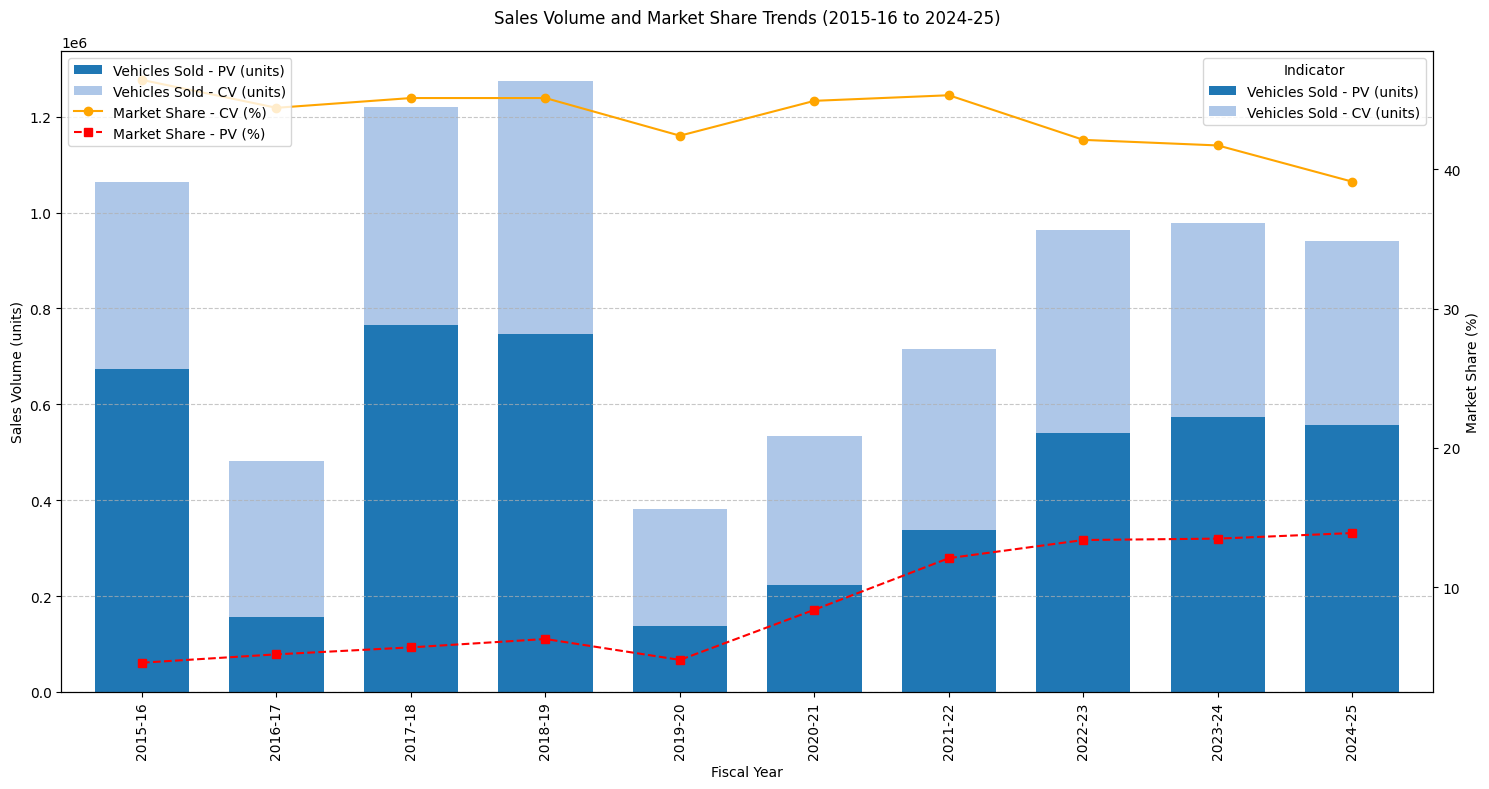

In [ ]:
# Filter for the relevant indicators and transpose the DataFrame
df_sales = df.loc[['Vehicles Sold - PV (units)', 'Vehicles Sold - CV (units)', 'Market Share - CV (%)', 'Market Share - PV (%)']].T
df_sales.index.name = 'Fiscal Year'
df_sales = df_sales.apply(pd.to_numeric)

# Create the plot
fig, ax1 = plt.subplots(figsize=(15, 8))
sales_colors = ['#1f77b4', '#aec7e8']
# --- Plot Sales Volume as a stacked bar chart on the primary axis (ax1) ---
df_sales[['Vehicles Sold - PV (units)', 'Vehicles Sold - CV (units)']].plot(kind='bar', stacked=True, ax=ax1, width=0.7,color=sales_colors )
ax1.set_xlabel('Fiscal Year')
ax1.set_ylabel('Sales Volume (units)', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_title('Sales Volume and Market Share Trends (2015-16 to 2024-25)', pad=20)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# --- Create a second axes for Market Share ---
ax2 = ax1.twinx()

# Plot Market Share as line charts on the secondary axis (ax2)
ax2.plot(ax1.get_xticks(), df_sales['Market Share - CV (%)'], marker='o', color='orange', linestyle='-', label='Market Share - CV (%)')
ax2.plot(ax1.get_xticks(), df_sales['Market Share - PV (%)'], marker='s', color='red', linestyle='--', label='Market Share - PV (%)')
ax2.set_ylabel('Market Share (%)', color='black')
ax2.tick_params(axis='y', labelcolor='black')
ax2.grid(False) # Disable grid for the secondary axis

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

# Final plot adjustments
plt.xticks(rotation=45, ha='right')
fig.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Step 1: Load dataset
# print("Loading dataset...")
df = pd.read_csv('BDM_data.csv')

# Step 2: Transpose dataframe
# print("Transposing dataframe...")
df = df.set_index('Indicator').T
df.index.name = 'Year'
# print(df.head())  # Show first few rows

# Step 3: Convert to numeric
# print("Converting data to numeric...")
df = df.apply(pd.to_numeric, errors='coerce')
# print(df.iloc[:5, :5])  # Show sample of numeric data

# Step 4: Combine GHG emissions
# print("Combining Scope 1 & 2 GHG emissions...")
df['GHG Emissions - Scope 1 & 2 (tCO2e)'] = df['GHG Emissions - Scope 1 (tCO2e)'] + df['GHG Emissions - Scope 2 (tCO2e)']
# print(df[['GHG Emissions - Scope 1 (tCO2e)', 'GHG Emissions - Scope 2 (tCO2e)', 'GHG Emissions - Scope 1 & 2 (tCO2e)']].tail())

# Step 5: Define market sizes and geo columns
market_sizes = {
    'India': 1.0,
    'China': 0.8,
    'UK': 0.6,
    'USA': 1.2,
    'Rest of Europe': 0.7,
    'Rest of World': 0.5
}

# Geographic revenue columns
geo_columns = [
    'Geographic Revenue - India (%)',
    'Geographic Revenue - China (%)',
    'Geographic Revenue - UK (%)',
    'Geographic Revenue - USA (%)',
    'Geographic Revenue - Rest of Europe (%)',
    'Geographic Revenue - Rest of World (%)'
]

# Step 6: Calculate BHI
print("Calculating Berry-Herfindahl Geographic Diversification...")
def calculate_bhi(row):
    shares = np.array([row[col] for col in geo_columns]) / 100
    sizes = np.array([market_sizes[col.split(' - ')[-1].replace(' (%)','')] for col in geo_columns])
    weighted_shares = shares * sizes
    sum_weighted = np.sum(weighted_shares)
    if sum_weighted == 0:
        return np.nan
    normalized_shares = weighted_shares / sum_weighted
    bhi = np.sum(normalized_shares ** 2)
    return 1 - bhi

df['Berry-Herfindahl Geographic Diversification'] = df.apply(calculate_bhi, axis=1)
print(df[['Berry-Herfindahl Geographic Diversification']].tail())

# Step 6: Define ERI metric groups by dimension
financial_metrics = [
    'Revenue (₹ Cr)', 'EBITDA (₹ Cr)', 'PAT (₹ Cr)',
    'Free Cash Flow (₹ Cr)', 'Net Debt/Equity Ratio'
]

operational_metrics = [
    'Vehicle Sales (Total units)', 'Market Share - CV (%)', 'Market Share - PV (%)',
    'Inventory Turnover ratio', 'Employee Turnover (%)'
]

market_metrics = [
    'Exports (units)', 'JLR Sold (units)', 'Berry-Herfindahl Geographic Diversification'
]

strategic_metrics = [
    'Capital Expenditure (₹ Cr)', 'Spend on R&D - TML (₹ Cr)',
    'Spend on R&D - JLR (GB£ mn)', 'Training Hours'
]

sustainability_metrics = [
    'GHG Emissions - Scope 1 & 2 (tCO2e)', 'Energy Consumption - Direct (GJ)',
    'Lost Time Injury Frequency Rate (LTIFR)', 'Total Employees'
]

# Step 7: Define normalization preference
higher_better = [
    'Revenue (₹ Cr)', 'EBITDA (₹ Cr)', 'PAT (₹ Cr)', 'Free Cash Flow (₹ Cr)',
    'Vehicle Sales (Total units)', 'Market Share - CV (%)', 'Market Share - PV (%)',
    'Inventory Turnover ratio', 'Exports (units)', 'JLR Sold (units)',
    'Capital Expenditure (₹ Cr)', 'Spend on R&D - TML (₹ Cr)', 'Spend on R&D - JLR (GB£ mn)',
    'Training Hours', 'Total Employees', 'Berry-Herfindahl Geographic Diversification'
]

lower_better = [
    'Net Debt/Equity Ratio', 'Employee Turnover (%)',
    'GHG Emissions - Scope 1 & 2 (tCO2e)', 'Energy Consumption - Direct (GJ)',
    'Lost Time Injury Frequency Rate (LTIFR)'
]

# Step 8: Normalize each metric to 0-1 scale
print("Normalizing metrics...")
normalized = pd.DataFrame(index=df.index)
all_metrics = financial_metrics + operational_metrics + market_metrics + strategic_metrics + sustainability_metrics
for metric in all_metrics:
    if metric not in df.columns:
        continue
    if metric in higher_better:
        normalized[metric] = (df[metric] - df[metric].min()) / (df[metric].max() - df[metric].min())
    elif metric in lower_better:
        normalized[metric] = (df[metric].max() - df[metric]) / (df[metric].max() - df[metric].min())
print(normalized['Exports (units)'])
print(normalized.head())

# Step 9: Calculate dimension scores by averaging normalized metrics in each
print("Calculating dimension scores...")
normalized['Financial Stability Score'] = normalized[financial_metrics].mean(axis=1)
normalized['Operational Health Score'] = normalized[operational_metrics].mean(axis=1)
normalized['Market & Geographic Score'] = normalized[market_metrics].mean(axis=1)
normalized['Strategic Investments Score'] = normalized[strategic_metrics].mean(axis=1)
normalized['Sustainability Score'] = normalized[sustainability_metrics].mean(axis=1)
print(normalized[[
    'Financial Stability Score', 'Operational Health Score', 'Market & Geographic Score',
    'Strategic Investments Score', 'Sustainability Score'
]].tail())

# Step 10: Define weights for dimensions (equal weights here, customize if needed)
weights = {
    'Financial Stability Score': 0.2,
    'Operational Health Score': 0.2,
    'Market & Geographic Score': 0.2,
    'Strategic Investments Score': 0.2,
    'Sustainability Score': 0.2
}

# Step 11: Calculate overall ERI as weighted sum of dimension scores
print("Calculating overall ERI...")
normalized['ERI'] = sum(normalized[dim] * weight for dim, weight in weights.items())
print(normalized[['ERI']].tail())

# Step 12: Format and output results
final_eri = normalized[[
    'Financial Stability Score', 'Operational Health Score', 'Market & Geographic Score',
    'Strategic Investments Score', 'Sustainability Score', 'ERI'
]].round(3)

print("Final ERI and dimension scores:")
print(final_eri)

final_eri.to_csv('tata_motors_eri_output.csv')  # Optional: save to CSV


Calculating Berry-Herfindahl Geographic Diversification...
Indicator  Berry-Herfindahl Geographic Diversification
Year                                                  
2020-21                                       0.803565
2021-22                                       0.815514
2022-23                                       0.760051
2023-24                                       0.781119
2024-25                                       0.775226
Normalizing metrics...
Year
2015-16    0.825188
2016-17    1.000000
2017-18    0.664814
2018-19    0.685690
2019-20    0.061778
2020-21    0.133116
2021-22    0.628053
2022-23    0.263197
2023-24    0.025018
2024-25    0.000000
Name: Exports (units), dtype: float64
         Revenue (₹ Cr)  EBITDA (₹ Cr)  PAT (₹ Cr)  Free Cash Flow (₹ Cr)  \
Year                                                                        
2015-16        0.151401       0.000000    0.317879               0.235398   
2016-17        0.134028       0.568983    0.181087         

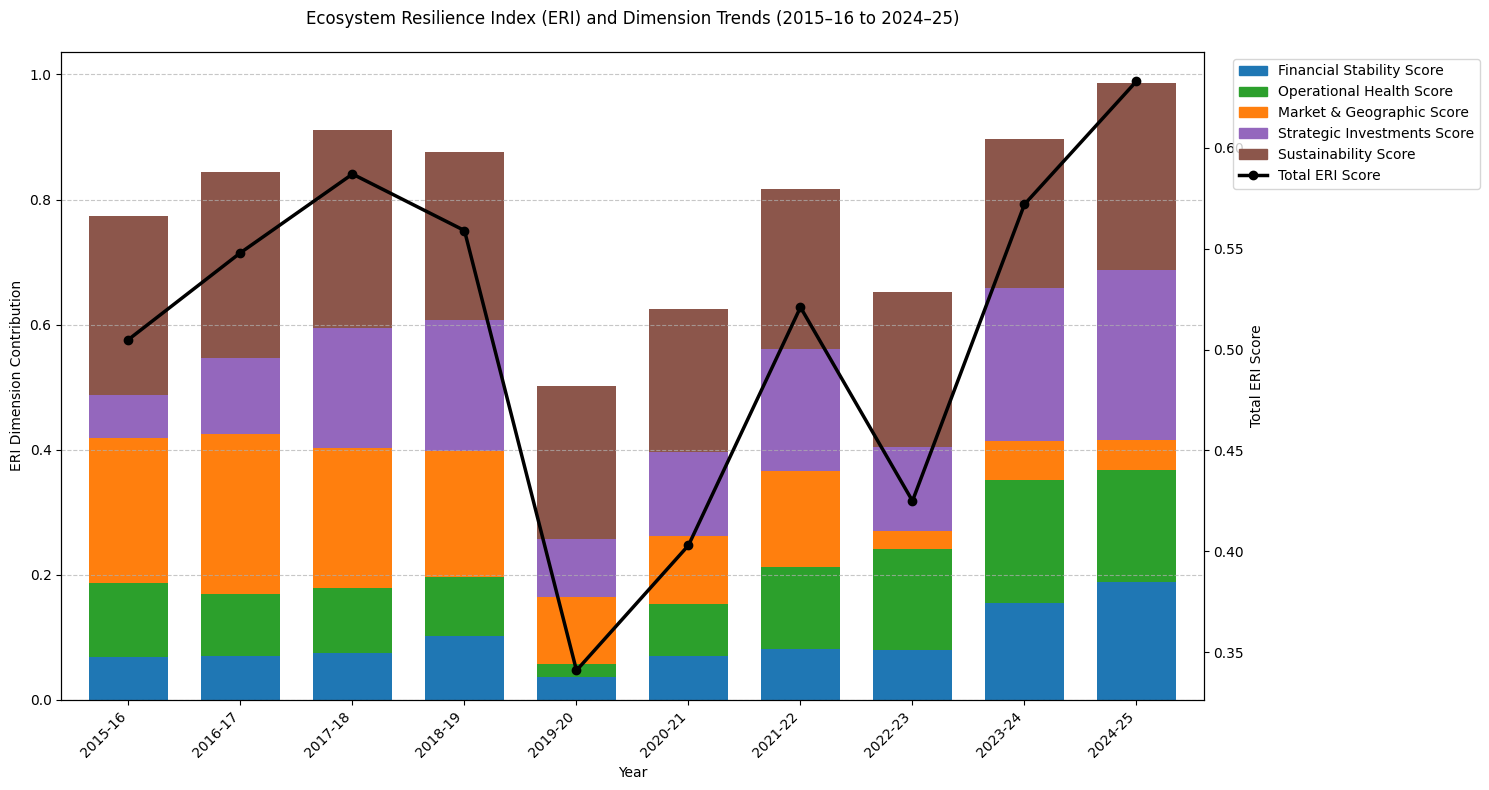

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Load the data ---
df = pd.read_csv('tata_motors_eri_output.csv')

# --- Define dimensions ---
dimensions = [
    "Financial Stability Score", "Operational Health Score",
    "Market & Geographic Score", "Strategic Investments Score", "Sustainability Score"
]

# --- Normalize contributions based on ERI ---
df_stack = df.copy()
for col in dimensions:
    df_stack[col] = df_stack[col] / df_stack[dimensions].sum(axis=1) * df["ERI"]

# --- Create the figure ---
fig, ax1 = plt.subplots(figsize=(15, 8))
eri_colors = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b']

# --- Plot stacked bar chart using Fiscal Year as x ---
df_stack[dimensions].plot(
    kind='bar', stacked=True, ax=ax1, width=0.7, color=eri_colors, legend=False
)
ax1.set_xlabel('Year')
ax1.set_ylabel('ERI Dimension Contribution', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_title('Ecosystem Resilience Index (ERI) and Dimension Trends (2015–16 to 2024–25)', pad=20)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# --- Replace x-axis numbers with Fiscal Year labels ---
ax1.set_xticks(range(len(df["Year"])))
ax1.set_xticklabels(df["Year"], rotation=45, ha='right')

# --- Secondary axis for ERI line ---
ax2 = ax1.twinx()
ax2.plot(range(len(df["Year"])), df["ERI"], marker='o', color='black', linewidth=2.5, label='Total ERI Score')
ax2.set_ylabel('Total ERI Score', color='black')
ax2.tick_params(axis='y', labelcolor='black')
ax2.grid(False)

# --- Combine legends (only outside one) ---
bars = [plt.Rectangle((0,0),1,1, color=c) for c in eri_colors]
labels = dimensions + ['Total ERI Score']
ax2.legend(bars + [plt.Line2D([0], [0], color='black', marker='o', linewidth=2.5)],
           labels, loc='upper left', bbox_to_anchor=(1.02, 1))

# --- Final touches ---
fig.tight_layout()
plt.show()
